# Rendering quality: puzzles, MuJoCo, and Franka

Compare `low`, `medium`, and `high` using the same LeWM/CEM baseline, seeds, and budgets. An adaptive-pooling encoder keeps the model parameter count identical across resolutions. The default is **high**. Model input resolution and presentation resolution are separate; the preset sets both. This changes visual observations, not the task dynamics or success thresholds.

This is a small validation experiment: 512 training pairs, 100 updates, two evaluation seeds, and 30 steps. Success/return are the task metrics; latent MSE scales can differ between independently trained encoders. Runs may share the GPU with other validation jobs; recorded timings are not a controlled hardware benchmark.

Run in an Isaac Lab 3.x GPU environment with the MuJoCo and notebook extras installed. All three experiments here use **RGB model observations**, including Franka. Every saved episode includes **GT**. The Franka GT object is placed at the requested target; the arm pose is not an expert demonstration.

The recorded Franka quality runs use the earlier arm action range. [Updated Franka experiments](FRANKA_RESULTS.md) use the full joint-limit mapping; rerunning this notebook will use that mapping too.

In [1]:
from datetime import datetime, timezone
from pathlib import Path

import torch
from IPython.display import Markdown, display
from torch import nn

from torch_world import plots
from torch_world.benchmarks import (
    cem_baseline,
    run_experiment,
    show_results,
    write_summary,
)
from torch_world.benchmarks.visualization import capture_frame
from torch_world.envs import QUALITY_PRESETS, BallPlate, FrankaCubeLift, Maze
from torch_world.models import LeWM

SEED, UPDATES = 7, 100
CAMPAIGN = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT_DIR = Path("runs/quality_comparison") / CAMPAIGN
planner_factory = cem_baseline
results = {}


def model_factory(observation_shape, action_dim):
    # Same parameter count at all input resolutions; replace this factory to compare models.
    encoder = nn.Sequential(
        nn.Conv2d(observation_shape[0], 16, 3, 2, 1),
        nn.GELU(),
        nn.Conv2d(16, 32, 3, 2, 1),
        nn.GELU(),
        nn.AdaptiveAvgPool2d((4, 4)),
        nn.Flatten(),
        nn.Linear(32 * 4 * 4, 32),
    )
    return LeWM(
        encoder,
        action_dim,
        embed_dim=32,
        history=1,
        depth=2,
        num_heads=4,
        head_dim=8,
        mlp_dim=64,
        proj_dim=64,
        dropout=0,
    )


def compare_quality(environment, **env_kwargs):
    runs, previews, titles = [], [], []
    for quality in QUALITY_PRESETS:
        with environment(quality=quality, **env_kwargs) as world:
            observation = world.reset(seed=SEED)
            for target in (False, True):
                frame = capture_frame(world, observation, target=target)
                # A common display size makes native resolution differences visible.
                previews.append(
                    torch.nn.functional.interpolate(
                        frame[None].float(),
                        (512, 512),
                        mode="nearest",
                    )[0].to(torch.uint8)
                )
                titles.append(getattr(world, "gt_label", "GT") if target else quality)
            runs.append(
                run_experiment(
                    world,
                    model_factory=model_factory,
                    planner_factory=planner_factory,
                    seed=SEED,
                    updates=UPDATES,
                    samples=512,
                    evaluation_seeds=2,
                    evaluation_steps=30,
                    model_config={"encoder": "adaptive-4x4", "capacity_fixed_across_resolutions": True},
                    output_dir=OUTPUT_DIR,
                )
            )
    display(plots.images(torch.stack(previews), titles=titles, ncols=2, size=3.4))
    table = [
        "| Quality | Input px | Display px | LeWM success | Random success | LeWM return | Artifacts |",
        "|---|---:|---:|---:|---:|---:|---|",
    ]
    for run in runs:
        visual = run["config"]["render_settings"]
        planned = run["evaluation"][run["planner_policy"]]
        random = run["evaluation"]["random"]
        table.append(
            f"| {visual['quality']} | {visual['observation_size']} | {visual['render_size']} | "
            f"{planned['success_rate']:.0%} | {random['success_rate']:.0%} | "
            f"{planned['mean_return']:.3f} | [Run]({run['run_dir']}) |"
        )
    display(Markdown("\n".join(table)))
    show_results(runs[-1])
    results[environment.__name__] = runs

## Maze

Distinct agent and goal symbols; square cells preserve the map geometry.

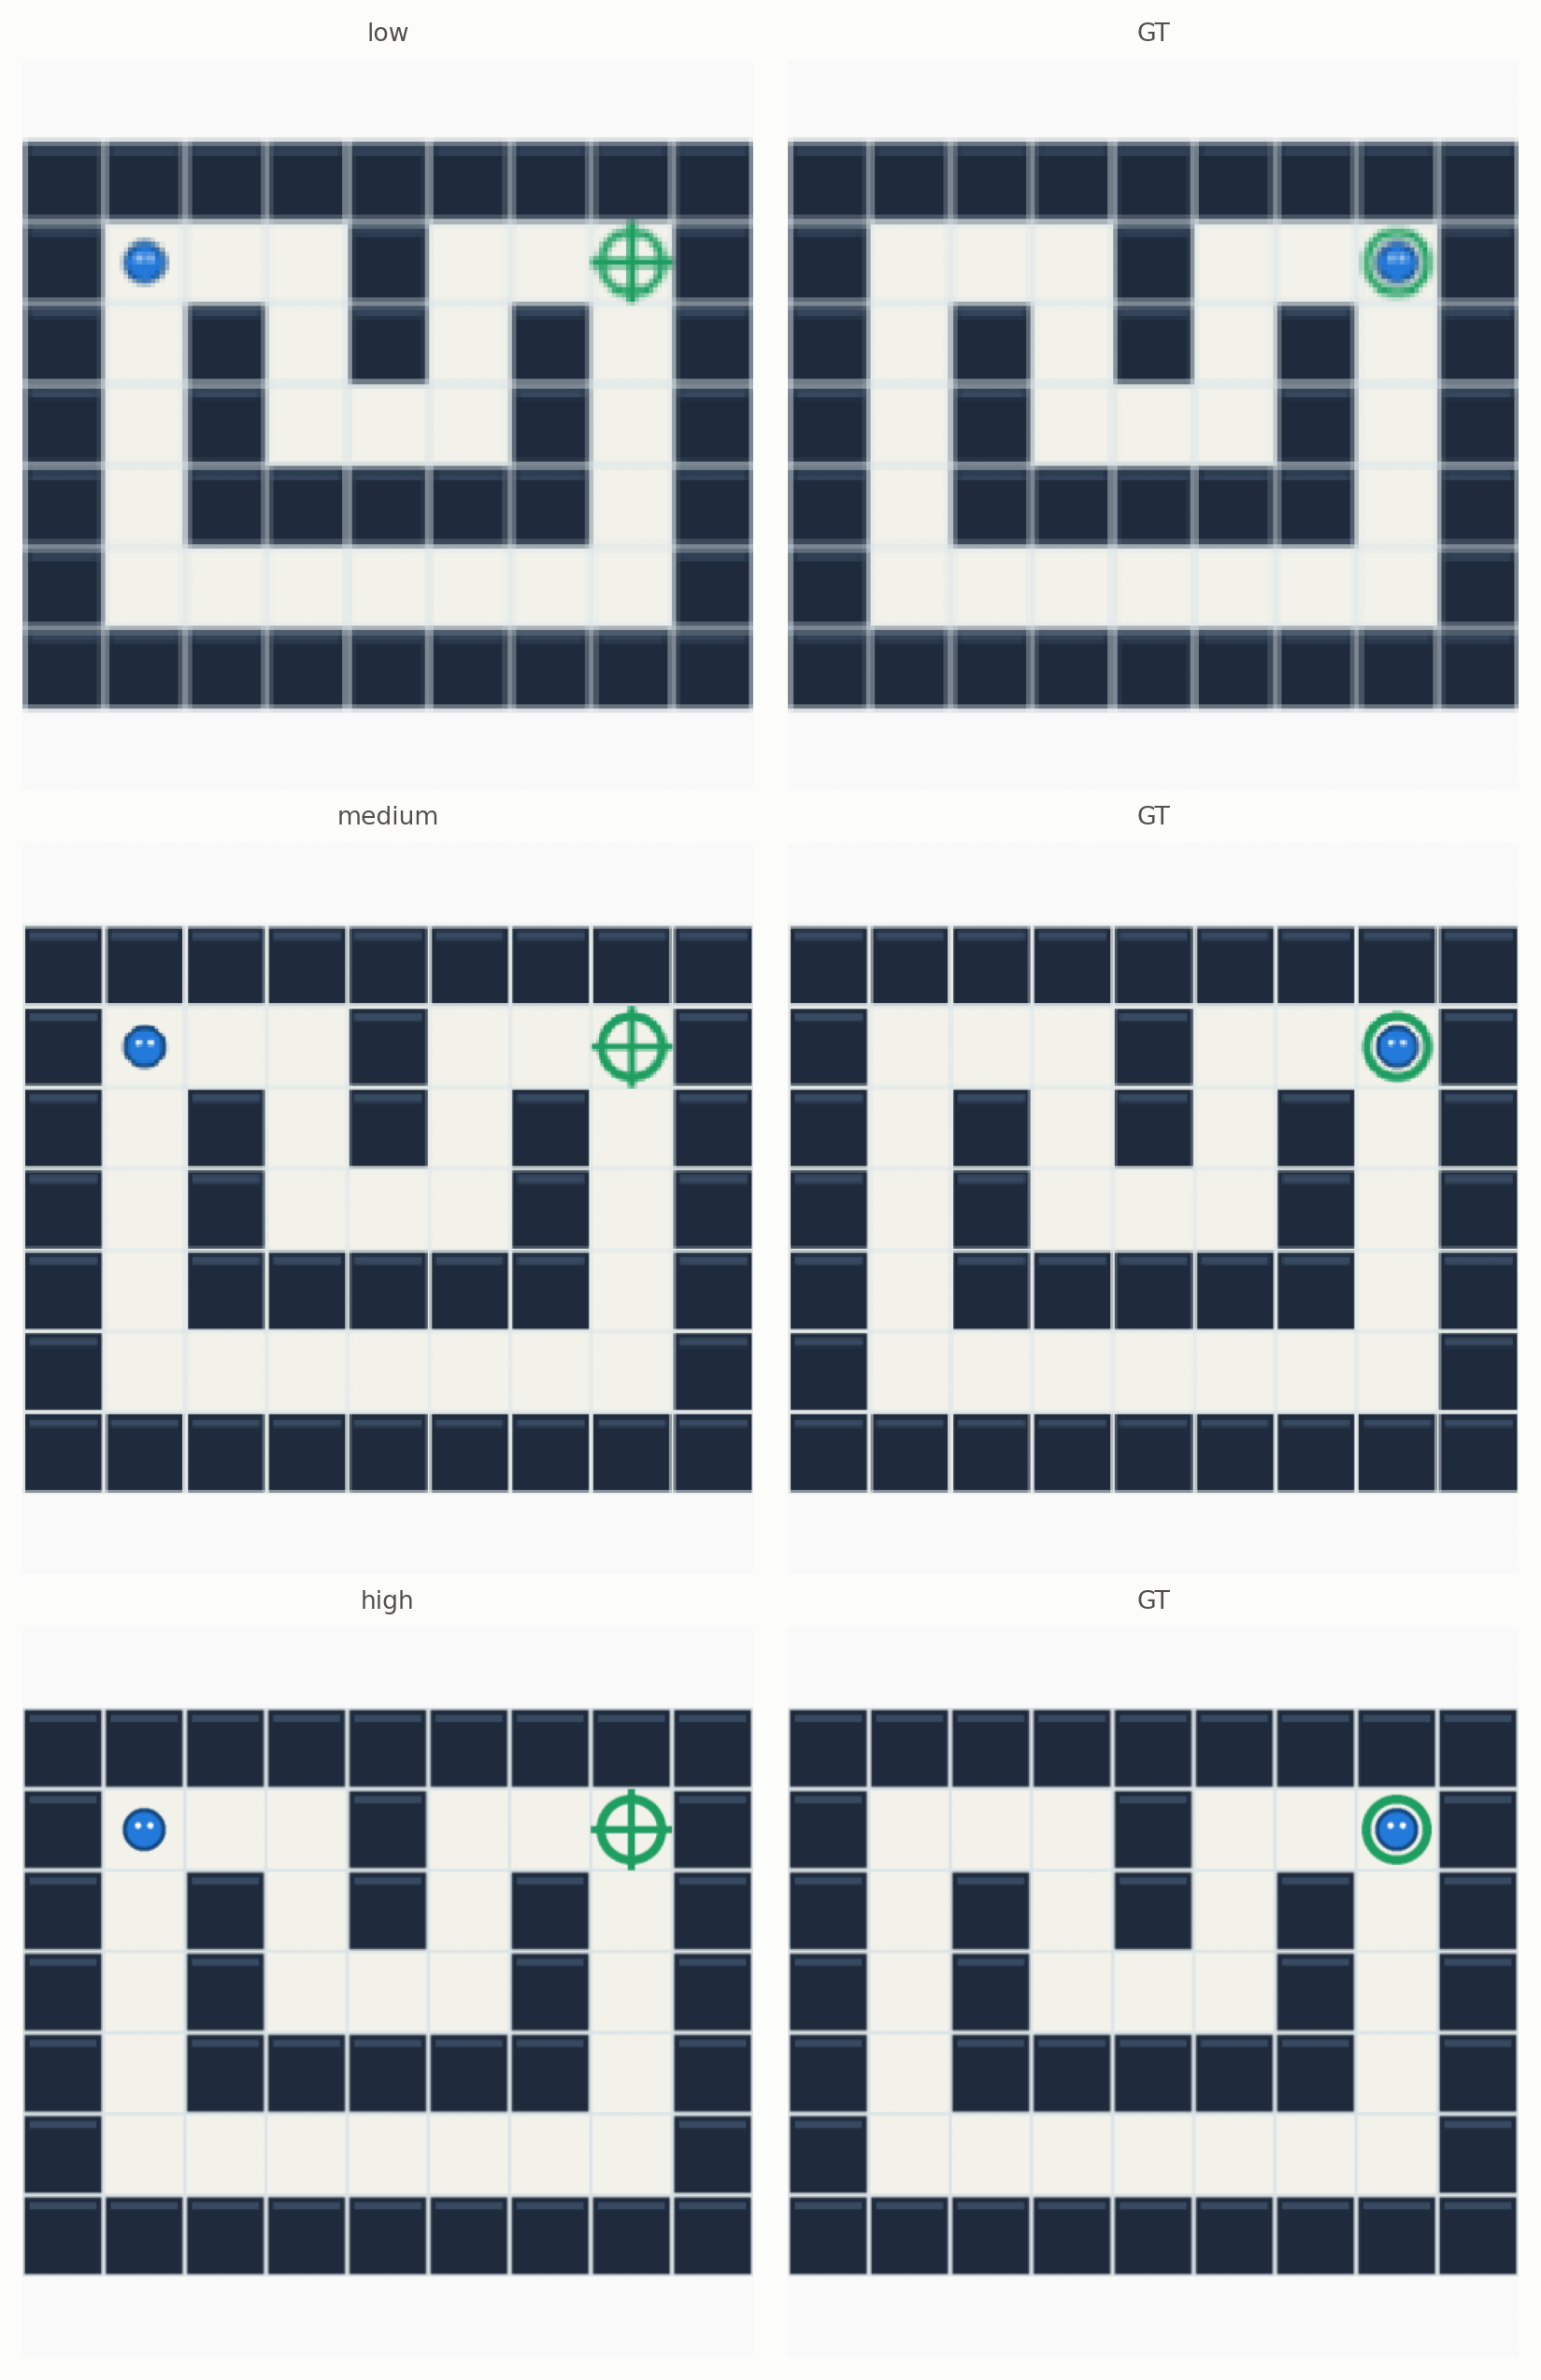

| Quality | Input px | Display px | LeWM success | Random success | LeWM return | Artifacts |
|---|---:|---:|---:|---:|---:|---|
| low | 32 | 160 | 0% | 0% | -0.300 | [Run](runs/quality_comparison/20261015T115010375079Z/Maze-v0/LeWM/20261015T115019744837Z-25c63224) |
| medium | 64 | 320 | 0% | 0% | -0.300 | [Run](runs/quality_comparison/20261015T115010375079Z/Maze-v0/LeWM/20261015T115028037943Z-ec7a85e1) |
| high | 128 | 512 | 0% | 0% | -0.300 | [Run](runs/quality_comparison/20261015T115010375079Z/Maze-v0/LeWM/20261015T115037684515Z-d4483f7e) |

**Maze-v0 · LeWM** — pixels observations, seed 7, 100 updates, 512 training / 128 held-out pairs. cuda; 7.3 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| LeWM | 0.0303 |
| Persistence | 0.0000 |

Latent standard deviation: **0.002**. Latent errors are comparable within this model; their scale differs between models.

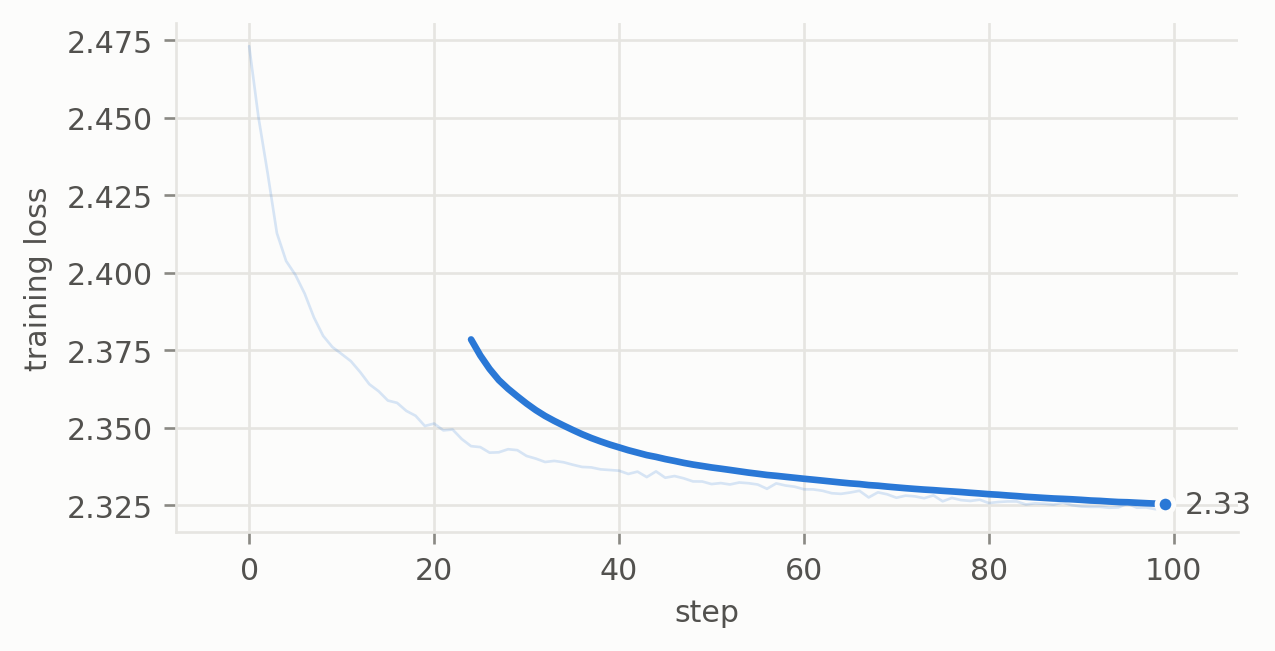

| Policy | Success | Steps | Final distance ↓ |
|---|---:|---:|---:|
| LeWM + CEM | 0% [0%, 66%] | 30.0 | 6.000 |
| random | 0% [0%, 66%] | 30.0 | 6.000 |

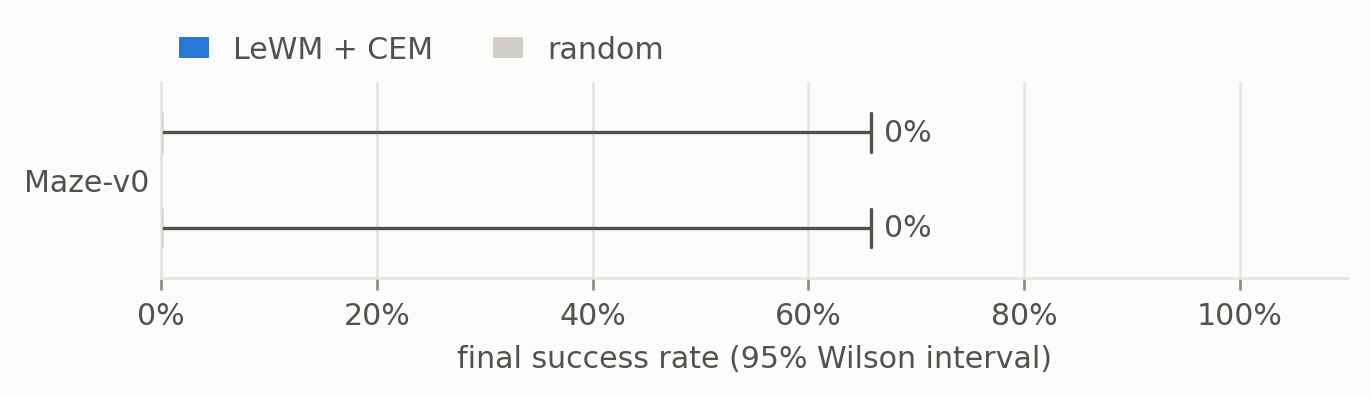

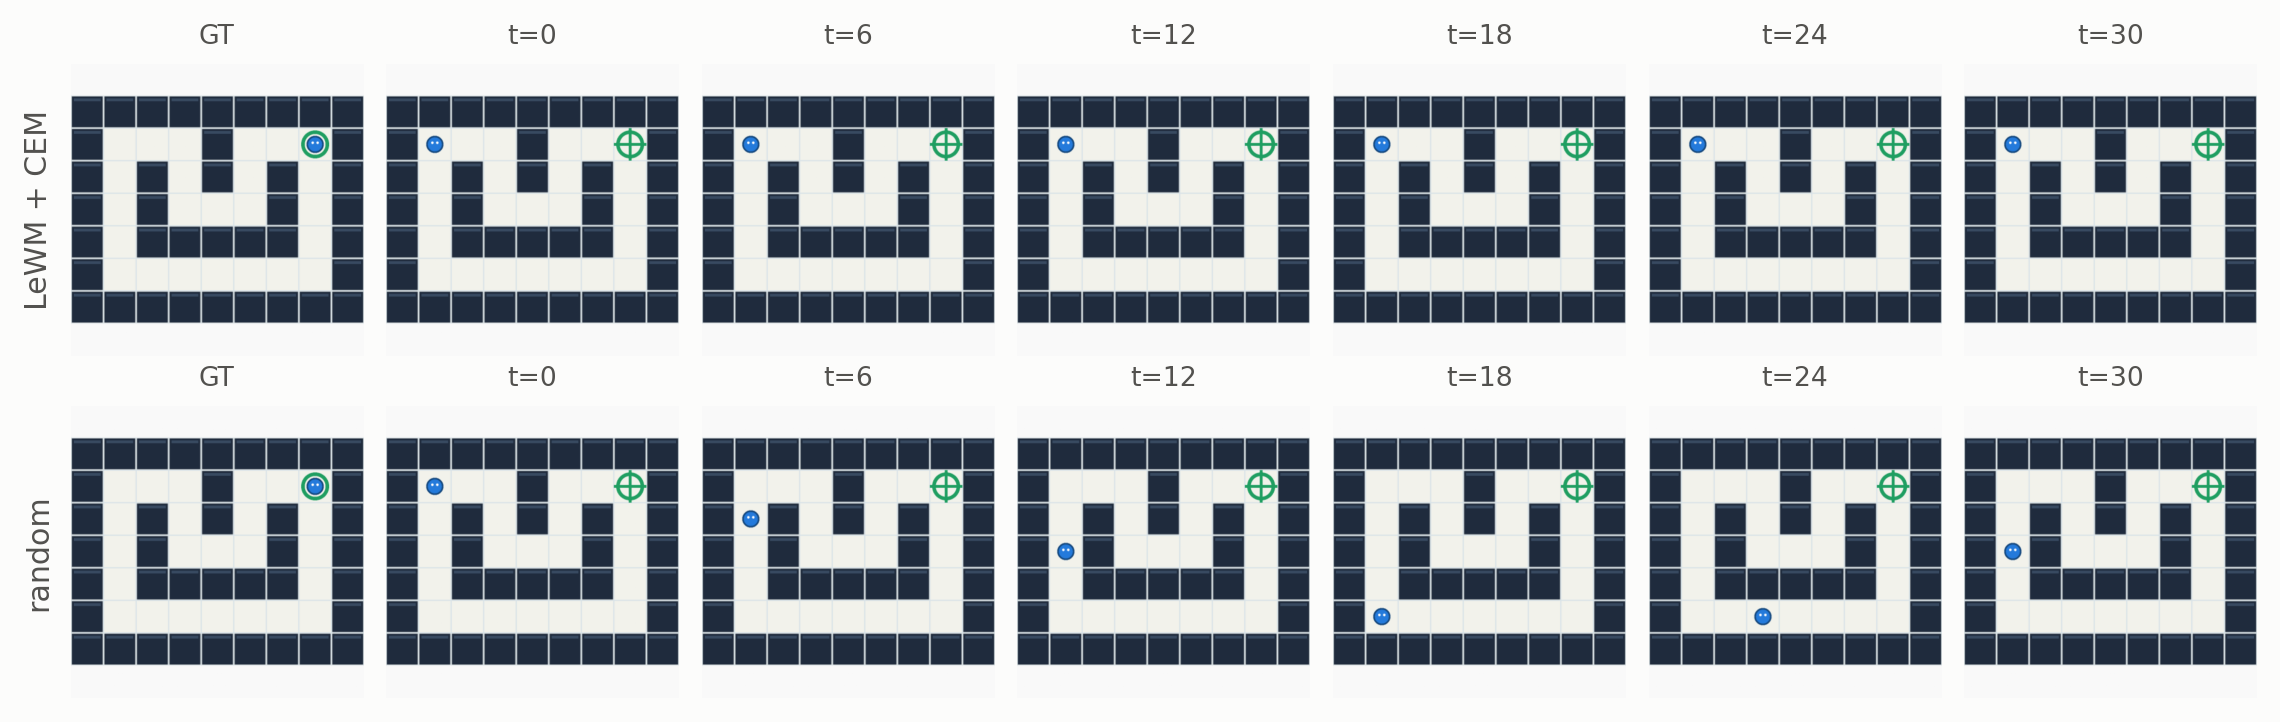

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

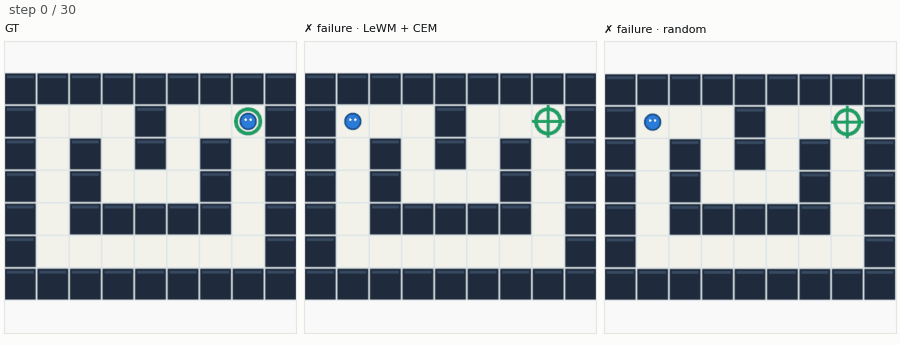

Static preview of the recorded episode. Rerun this cell to view the animation.

In [2]:
compare_quality(Maze)

## BallPlate

Orange ball on a blue plate, a fitted task camera, shadows, and antialiasing.

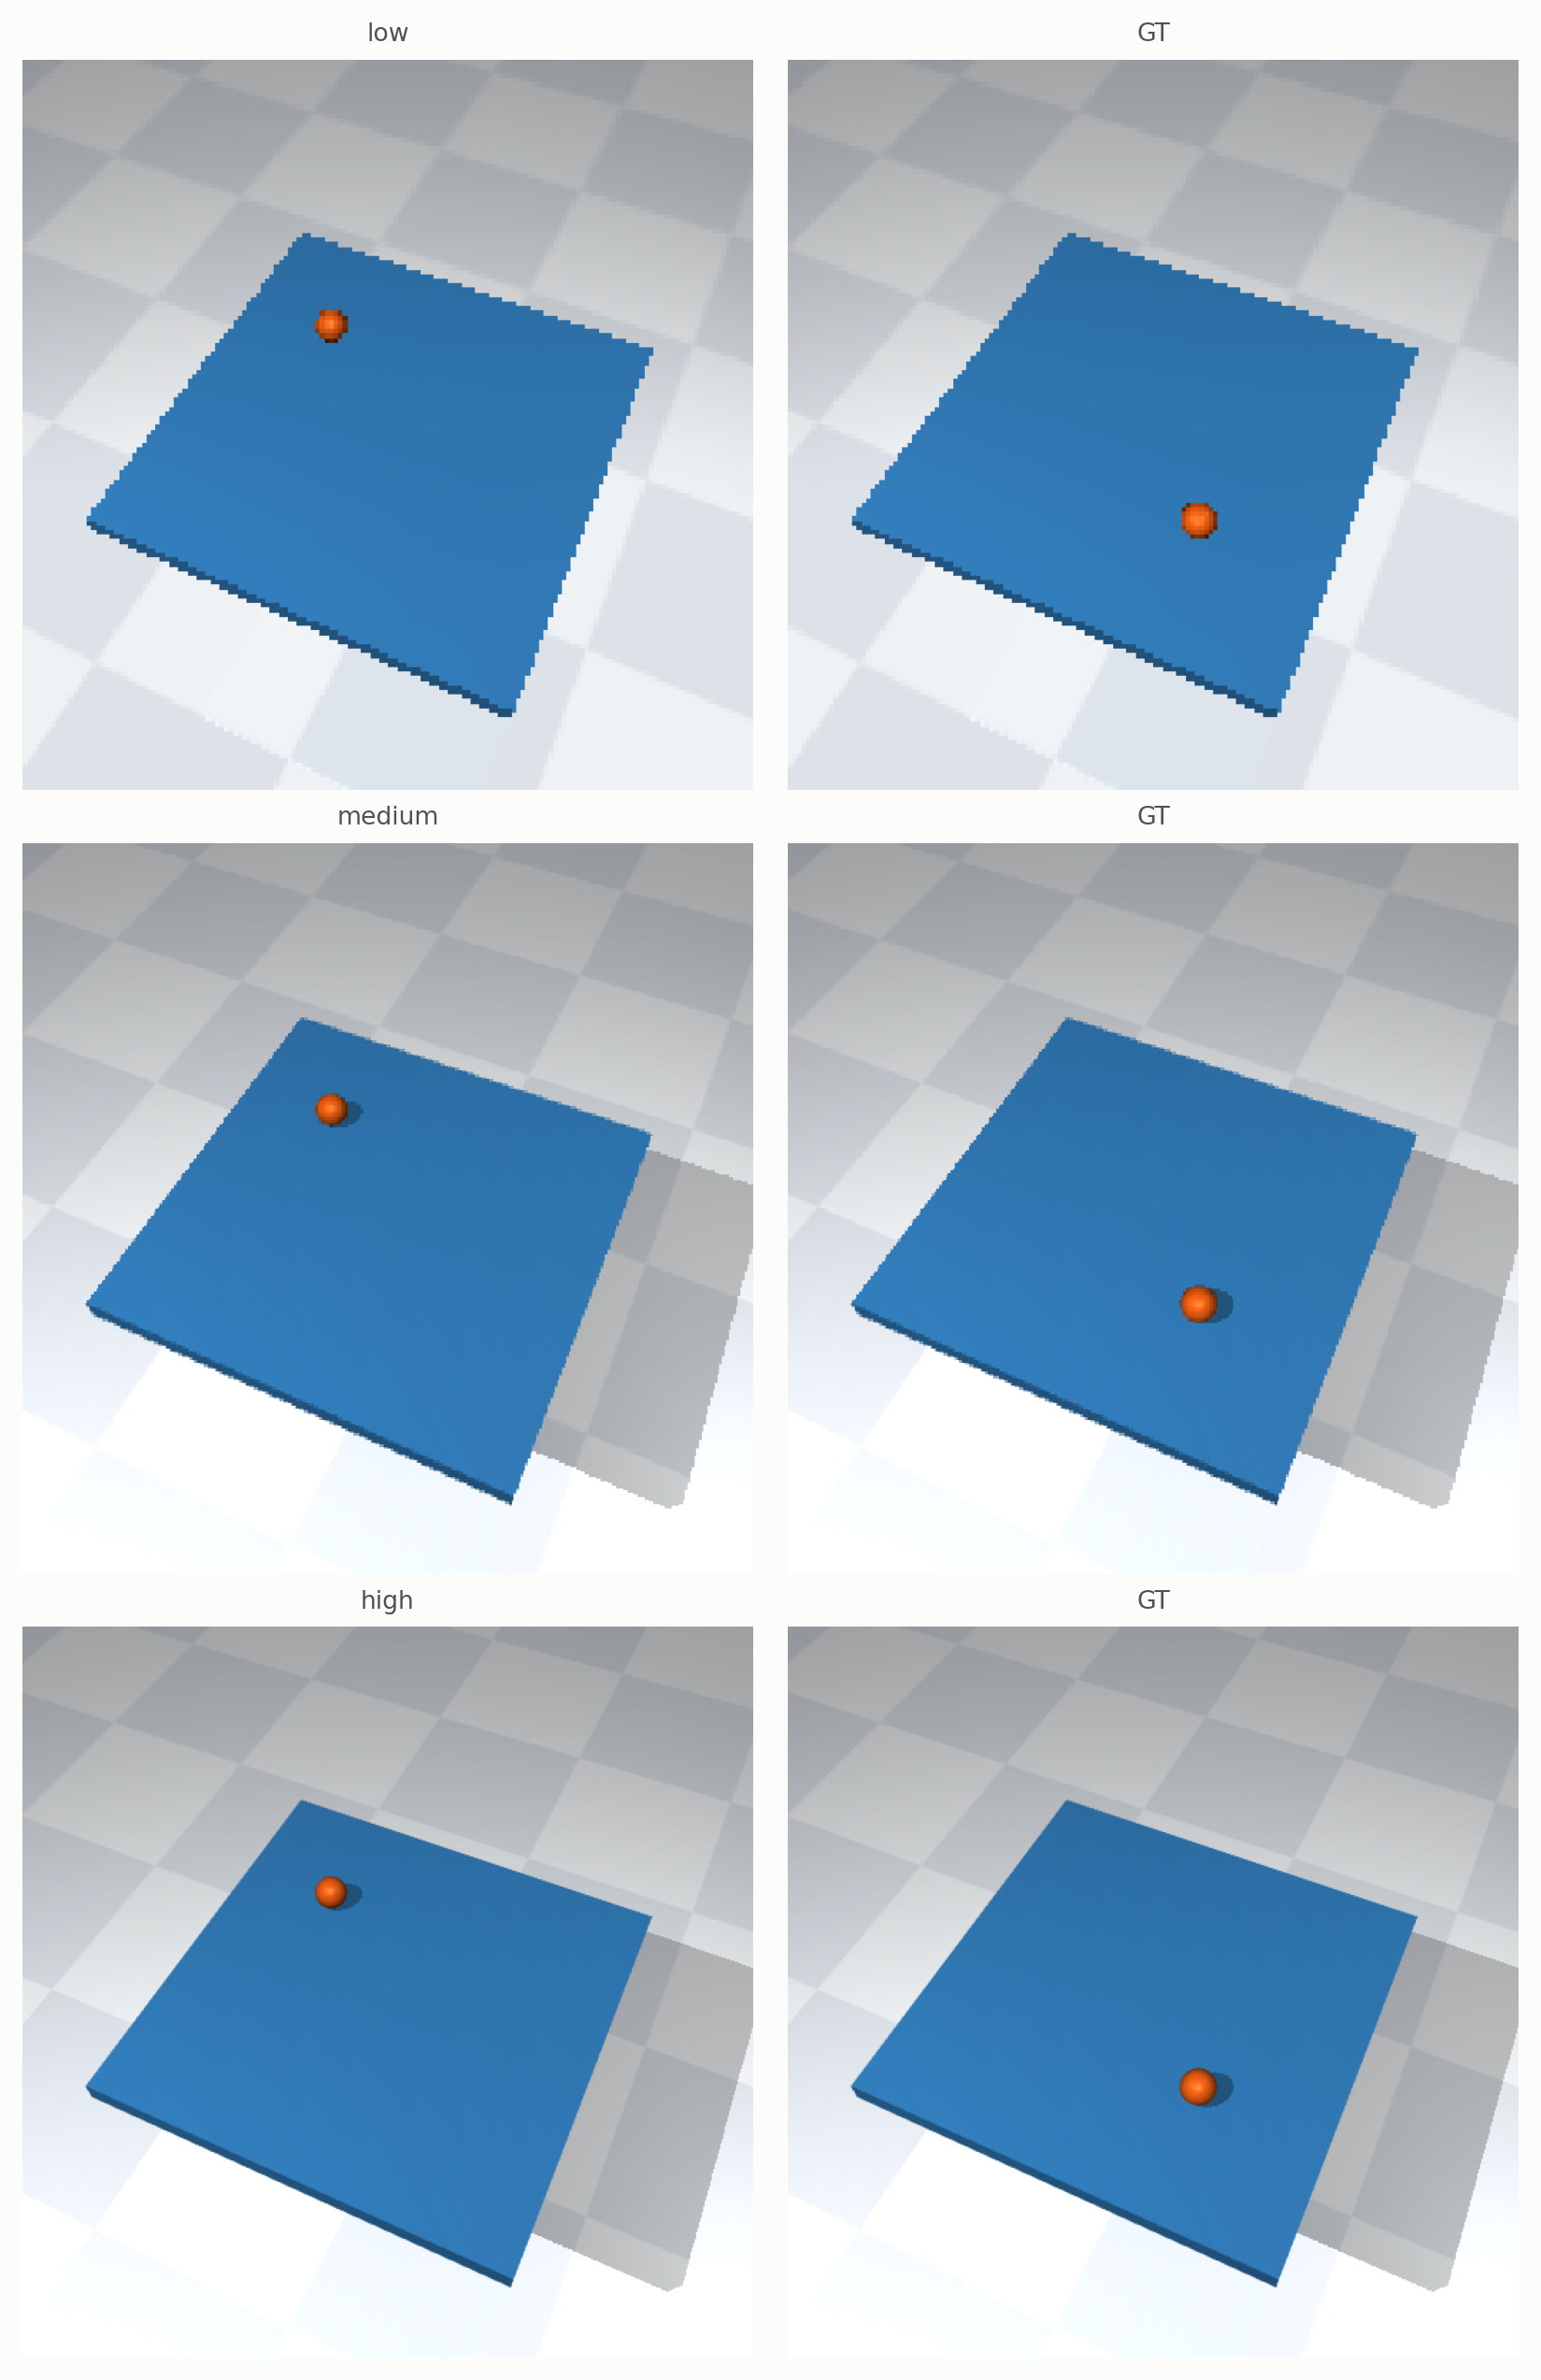

| Quality | Input px | Display px | LeWM success | Random success | LeWM return | Artifacts |
|---|---:|---:|---:|---:|---:|---|
| low | 32 | 160 | 0% | 0% | -263.077 | [Run](runs/quality_comparison/20261015T115010375079Z/BallPlate-v0/LeWM/20261015T115053078907Z-38ffcf89) |
| medium | 64 | 320 | 0% | 0% | -253.814 | [Run](runs/quality_comparison/20261015T115010375079Z/BallPlate-v0/LeWM/20261015T115105153166Z-9b3ec136) |
| high | 128 | 512 | 0% | 0% | -264.620 | [Run](runs/quality_comparison/20261015T115010375079Z/BallPlate-v0/LeWM/20261015T115122239493Z-7e3540d3) |

**BallPlate-v0 · LeWM** — pixels observations, seed 7, 100 updates, 512 training / 128 held-out pairs. cuda; 13.8 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| LeWM | 45.5510 |
| Persistence | 0.0009 |

Latent standard deviation: **0.087**. Latent errors are comparable within this model; their scale differs between models.

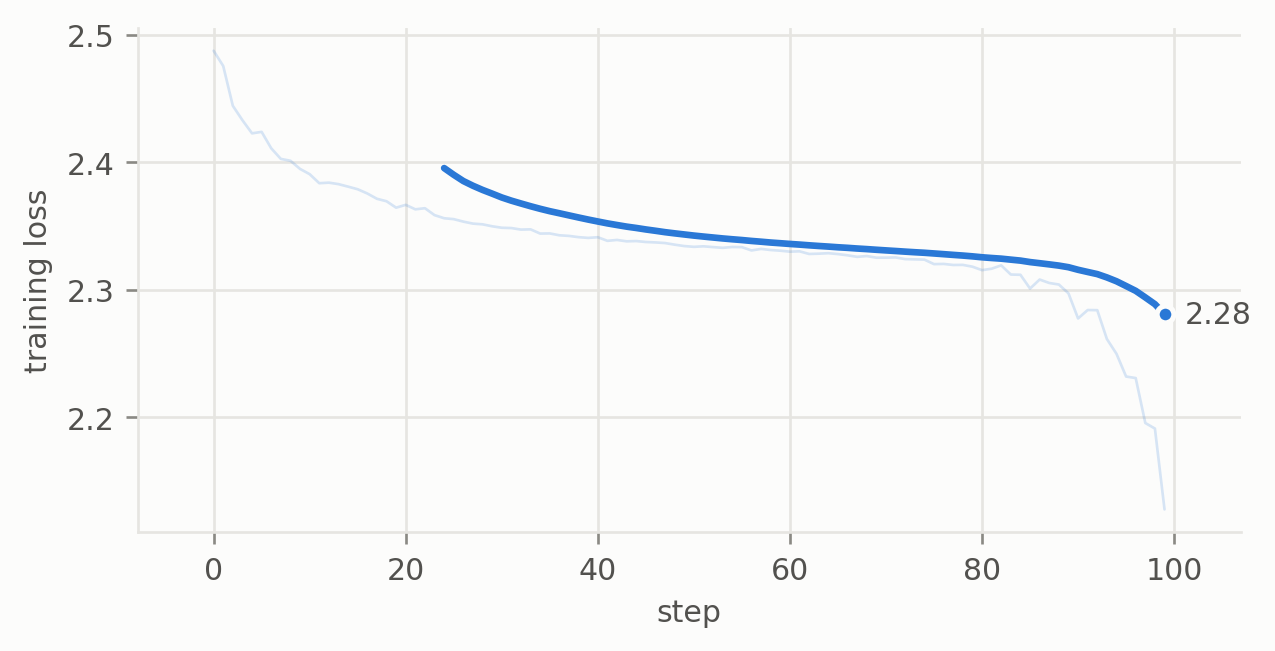

| Policy | Success | Steps | Final distance ↓ |
|---|---:|---:|---:|
| LeWM + CEM | 0% [0%, 66%] | 30.0 | 9.685 |
| random | 0% [0%, 66%] | 30.0 | 8.745 |

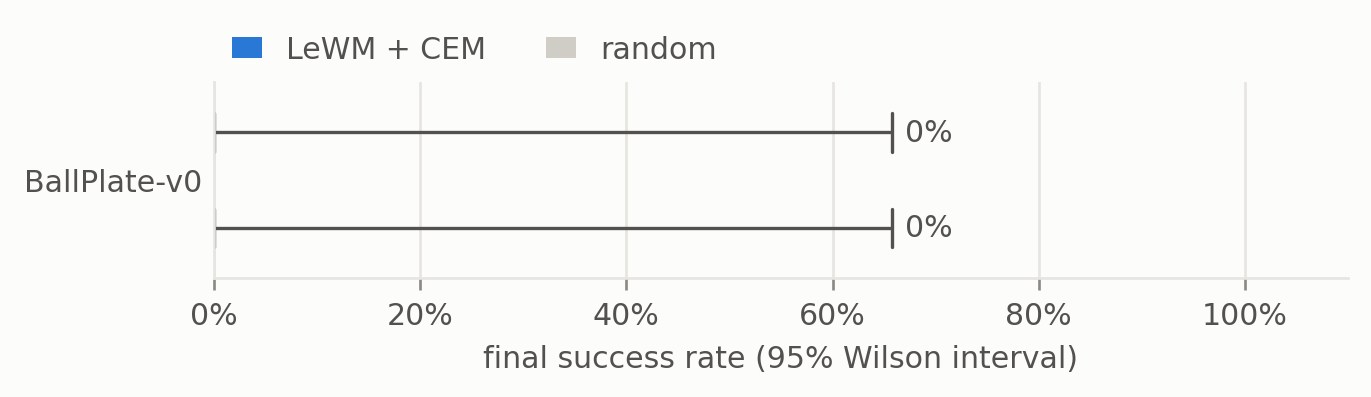

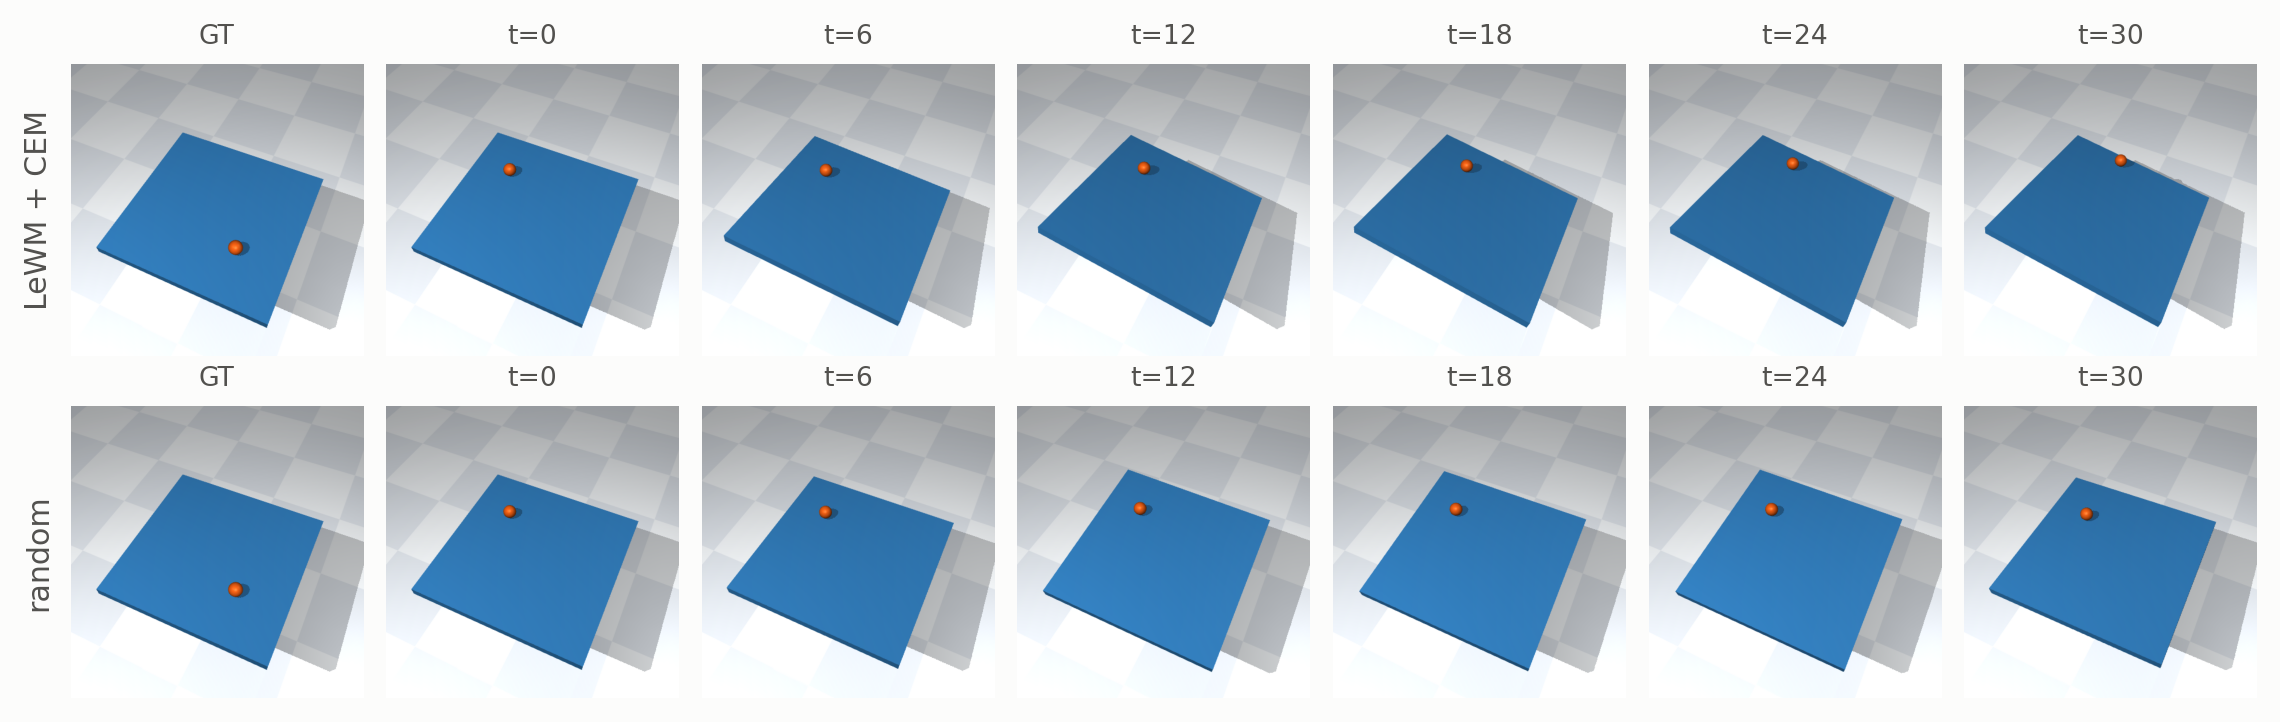

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

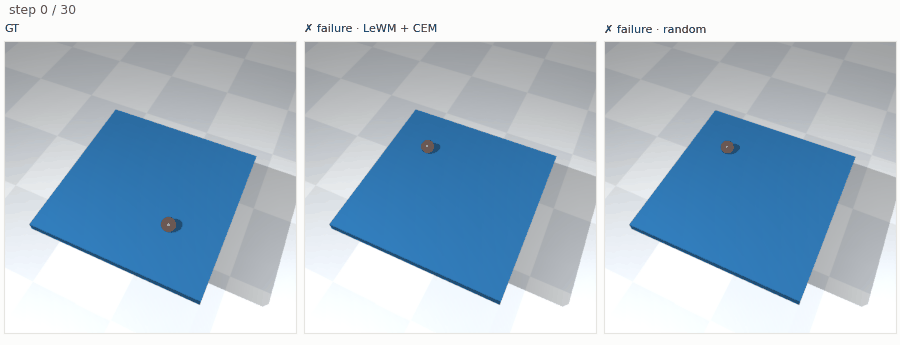

Static preview of the recorded episode. Rerun this cell to view the animation.

In [3]:
compare_quality(BallPlate)

## FrankaCubeLift

Actual articulated Franka meshes, cube, table, and green target. High quality uses a supersampled simulator camera.

Seed not set for the environment. The environment creation may not be deterministic.


[INFO]: Base environment:
	Environment device    : cuda:0
	Environment seed      : None
	Physics step-size     : 0.008333333333333333
	Rendering step-size   : 0.03333333333333333
	Environment step-size : 0.03333333333333333


I: Initializing Version 2.72.3-release.7151+gl.5390bed9
I: Client ID: D4QSZ2FX
I: Not using Hub: Hub not found
I: Successfully created S3 provider for https://omniverse-content-production.s3-us-west-2.amazonaws.com


I: Using CloudFront http://dcb18d6mfegct.cloudfront.net/, List = No
Serving remote assets from the local cache under '/tmp'. Each copy is checked against the server before use; delete the directory to force a full re-download.


/clusterhome/kleyton/xevals-isaaclab-validation/IsaacLab/source/isaaclab_newton/isaaclab_newton/cloner/replicate.py:132: FutureWarning: Newton shape color replacement is enabled; this workaround will be deprecated in a future release.
  replace_newton_builder_shape_colors(builder, stage)


...

/clusterhome/kleyton/xevals-isaaclab-validation/IsaacLab/source/isaaclab_newton/isaaclab_newton/cloner/newton_clone_utils.py:147: FutureWarning: Newton shape color replacement is enabled; this workaround will be deprecated in a future release.
  replace_newton_builder_shape_colors(builder, stage)


[INFO]: Time taken for scene creation Last: 0.528161 s, Mean: 0.950090 s, Std: 0.742965 s, N: 3
[INFO]: Scene manager:  <class InteractiveScene>
	Number of environments: 1
	Environment spacing   : 2.5
	Source prim name      : /World/envs/env_0
	Global prim paths     : []
	Replicate physics     : True


Failed to get root com velocity. If the articulation is fixed, this is expected. Setting root com velocity to zeros.


Finalize builder took: Last: 4.788444 s, Mean: 4.541237 s, Std: 0.665553 s, N: 3
Initialize solver took: Last: 0.071462 s, Mean: 0.653258 s, Std: 0.978796 s, N: 3


CUDA graph took: Last: 1.000072 s, Mean: 1.327861 s, Std: 0.591564 s, N: 3
[INFO]: Time taken for simulation start Last: 5.931222 s, Mean: 6.678600 s, Std: 1.075185 s, N: 3
[INFO] Command Manager:  <CommandManager> contains 0 active terms.
+----------------------+
| Active Command Terms |
+-------+------+-------+
| Index | Name |  Type |
+-------+------+-------+
+-------+------+-------+

[INFO] Event Manager:  <EventManager> contains 1 active terms.
+-------------------------------------+
| Active Event Terms in Mode: 'reset' |
+------------------+------------------+
|      Index       | Name             |
+------------------+------------------+
|        0         | reset            |
+------------------+------------------+

[INFO] Recorder Manager:  <RecorderManager> contains 0 active terms.
+-----------------------+
| Active Recorder Terms |
+------------+----------+
|   Index    | Name     |
+------------+----------+
+------------+----------+

[INFO] Action Manager:  <ActionManager>

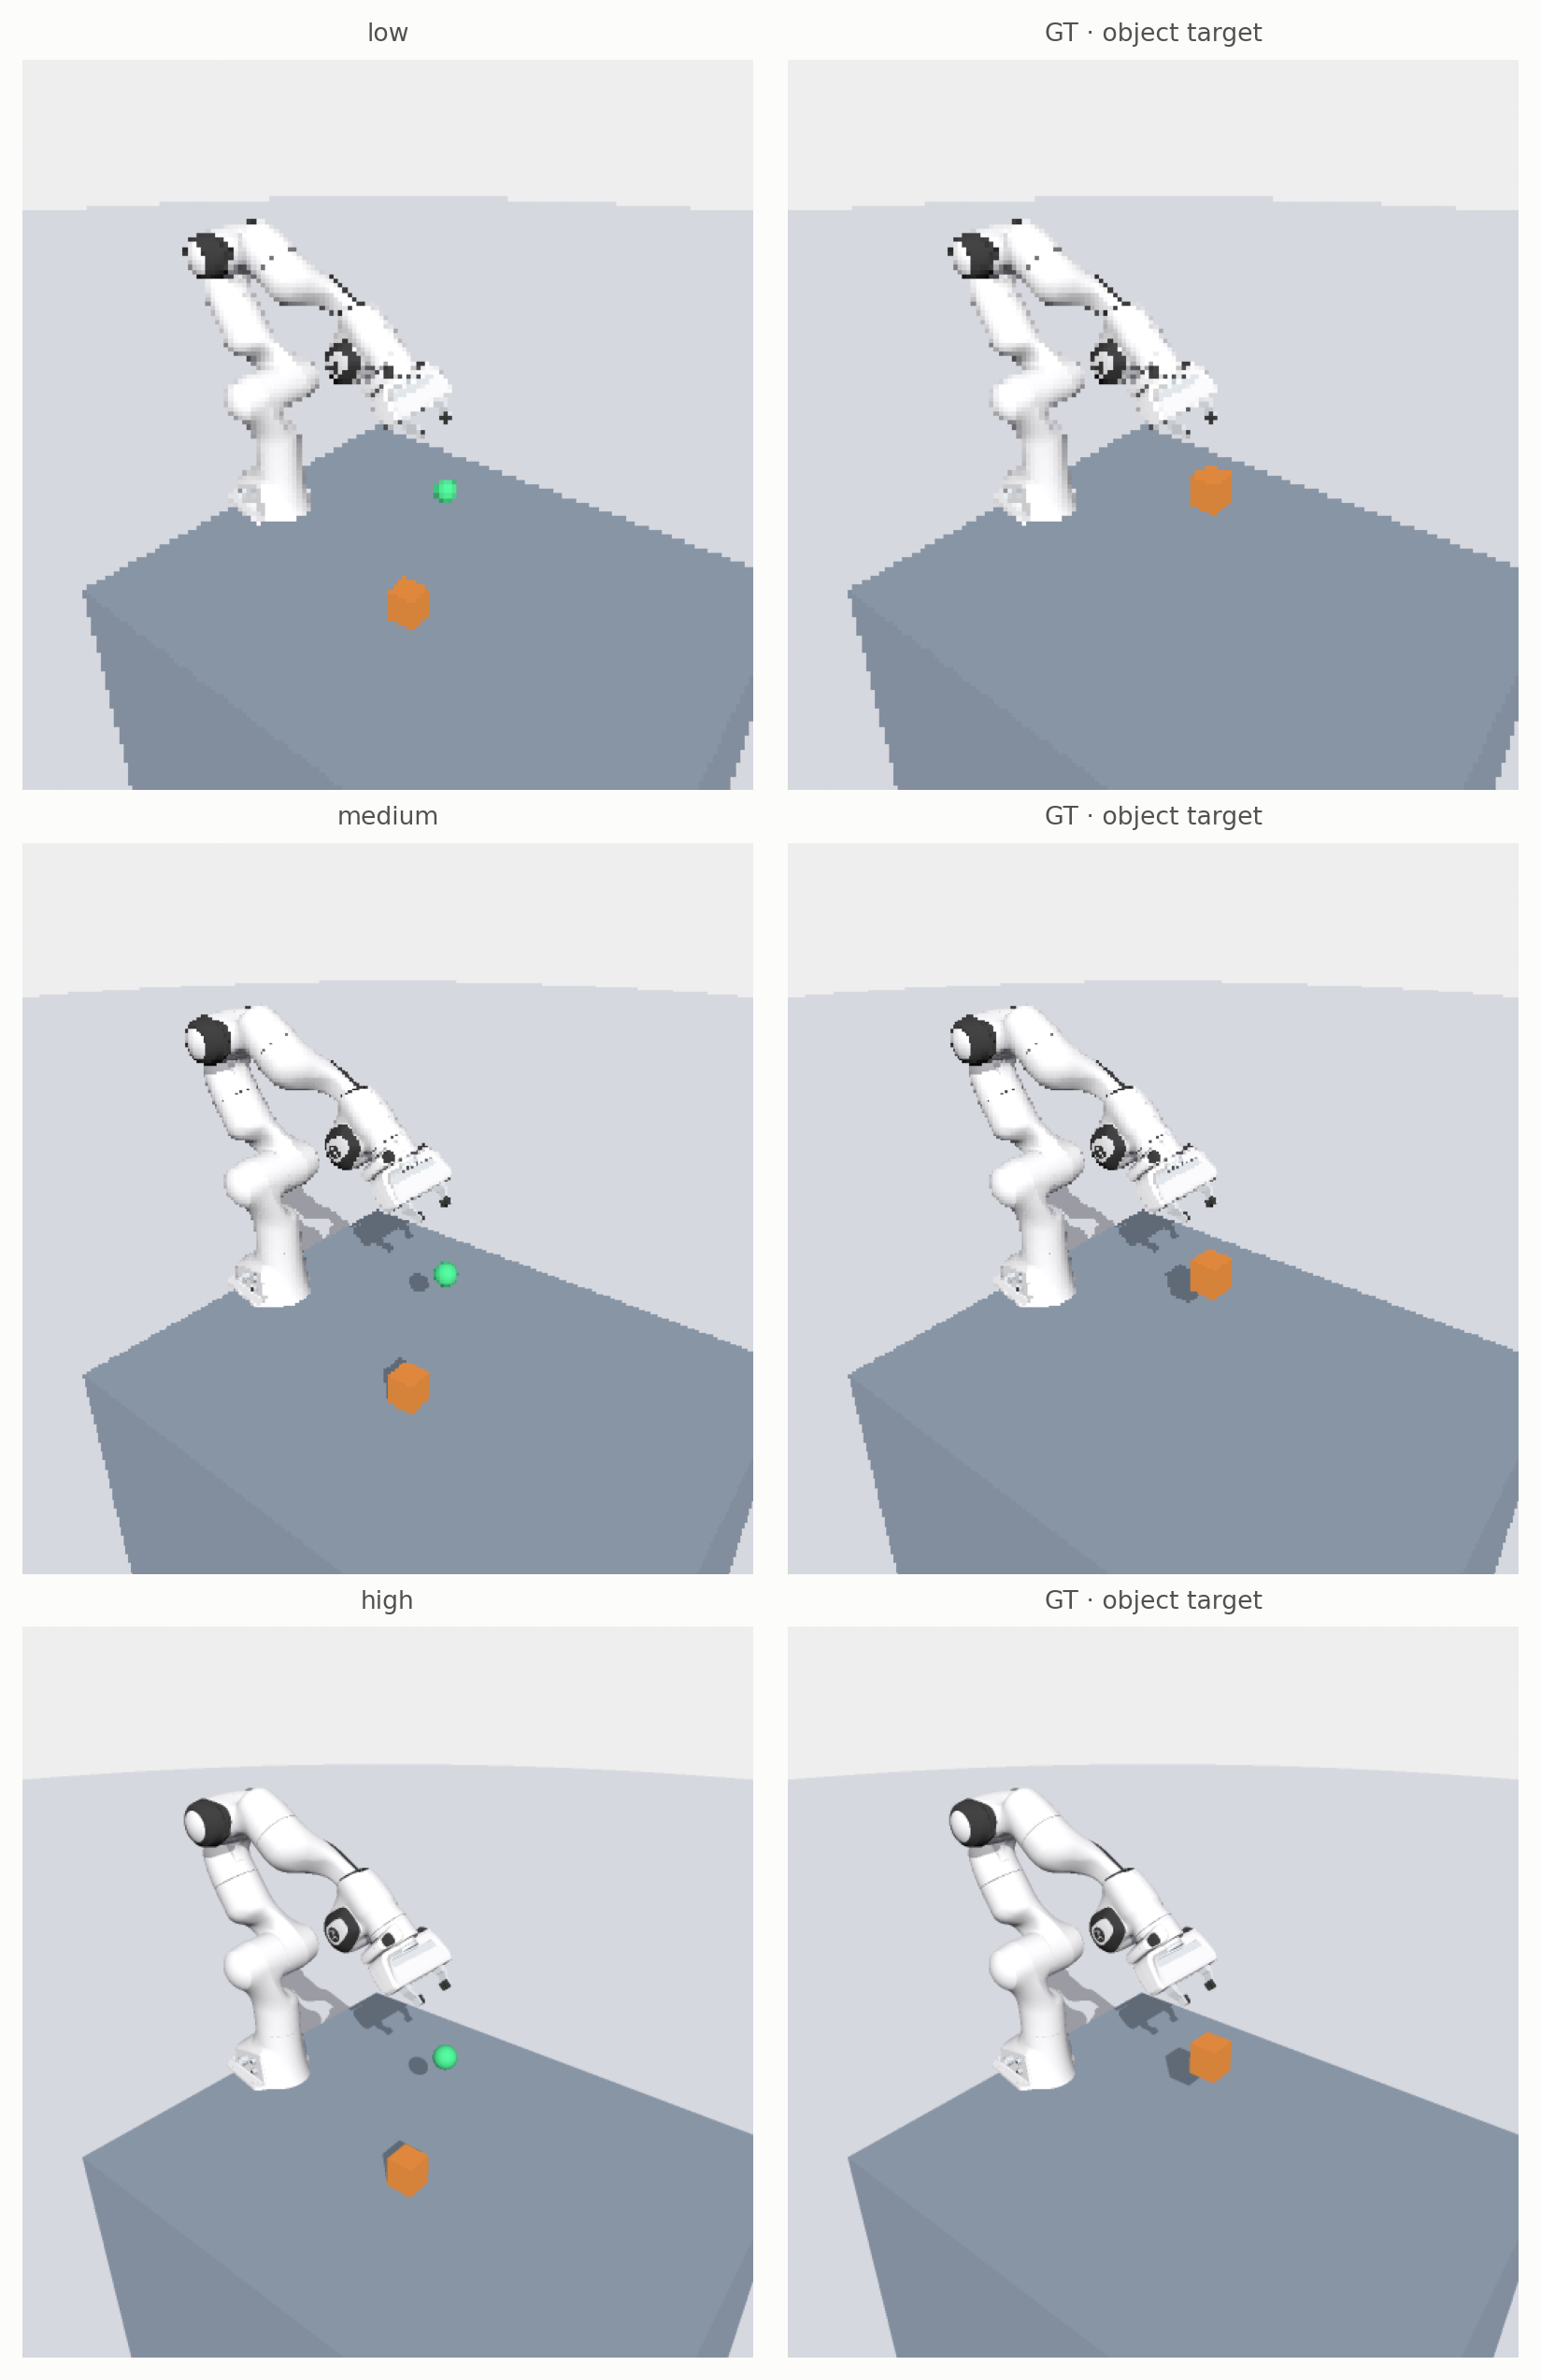

| Quality | Input px | Display px | LeWM success | Random success | LeWM return | Artifacts |
|---|---:|---:|---:|---:|---:|---|
| low | 32 | 160 | 0% | 0% | -0.247 | [Run](runs/quality_comparison/20261015T115010375079Z/FrankaCubeLift-v0/LeWM/20261015T115238051715Z-d4607e46) |
| medium | 64 | 320 | 0% | 0% | -0.247 | [Run](runs/quality_comparison/20261015T115010375079Z/FrankaCubeLift-v0/LeWM/20261015T115338256588Z-8cb31eba) |
| high | 128 | 512 | 0% | 0% | -0.247 | [Run](runs/quality_comparison/20261015T115010375079Z/FrankaCubeLift-v0/LeWM/20261015T115446794412Z-4d65d4d1) |

**FrankaCubeLift-v0 · LeWM** — pixels observations, seed 7, 100 updates, 512 training / 128 held-out pairs. cuda; 56.2 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| LeWM | 47.1915 |
| Persistence | 0.2340 |

Latent standard deviation: **0.674**. Latent errors are comparable within this model; their scale differs between models.

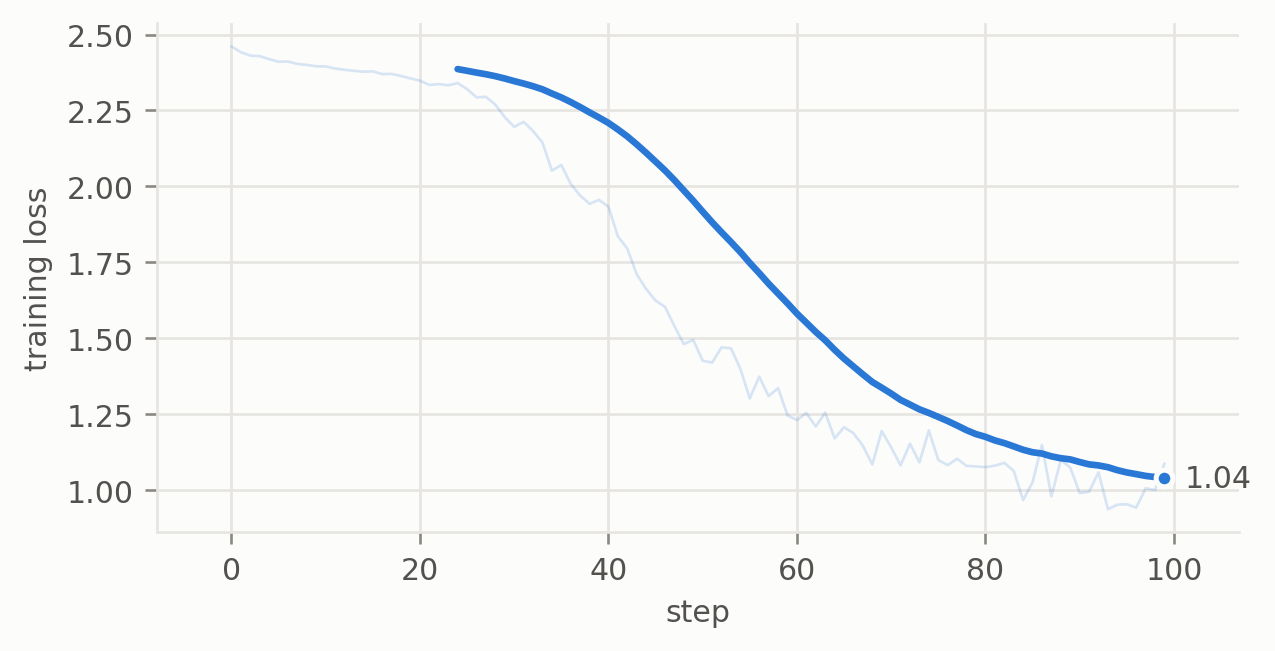

| Policy | Success | Steps | Return ↑ |
|---|---:|---:|---:|
| LeWM + CEM | 0% [0%, 66%] | 30.0 | -0.247 |
| random | 0% [0%, 66%] | 30.0 | -0.249 |

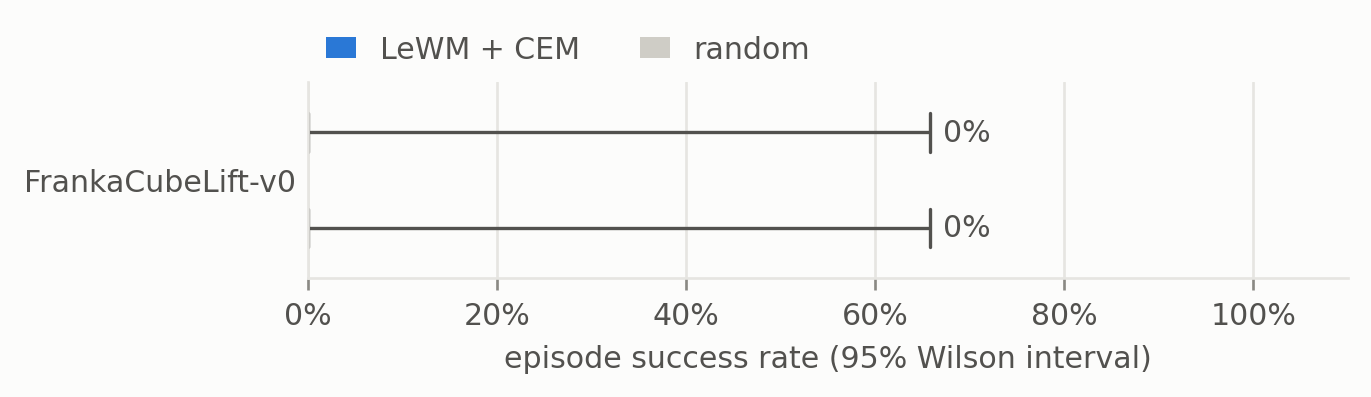

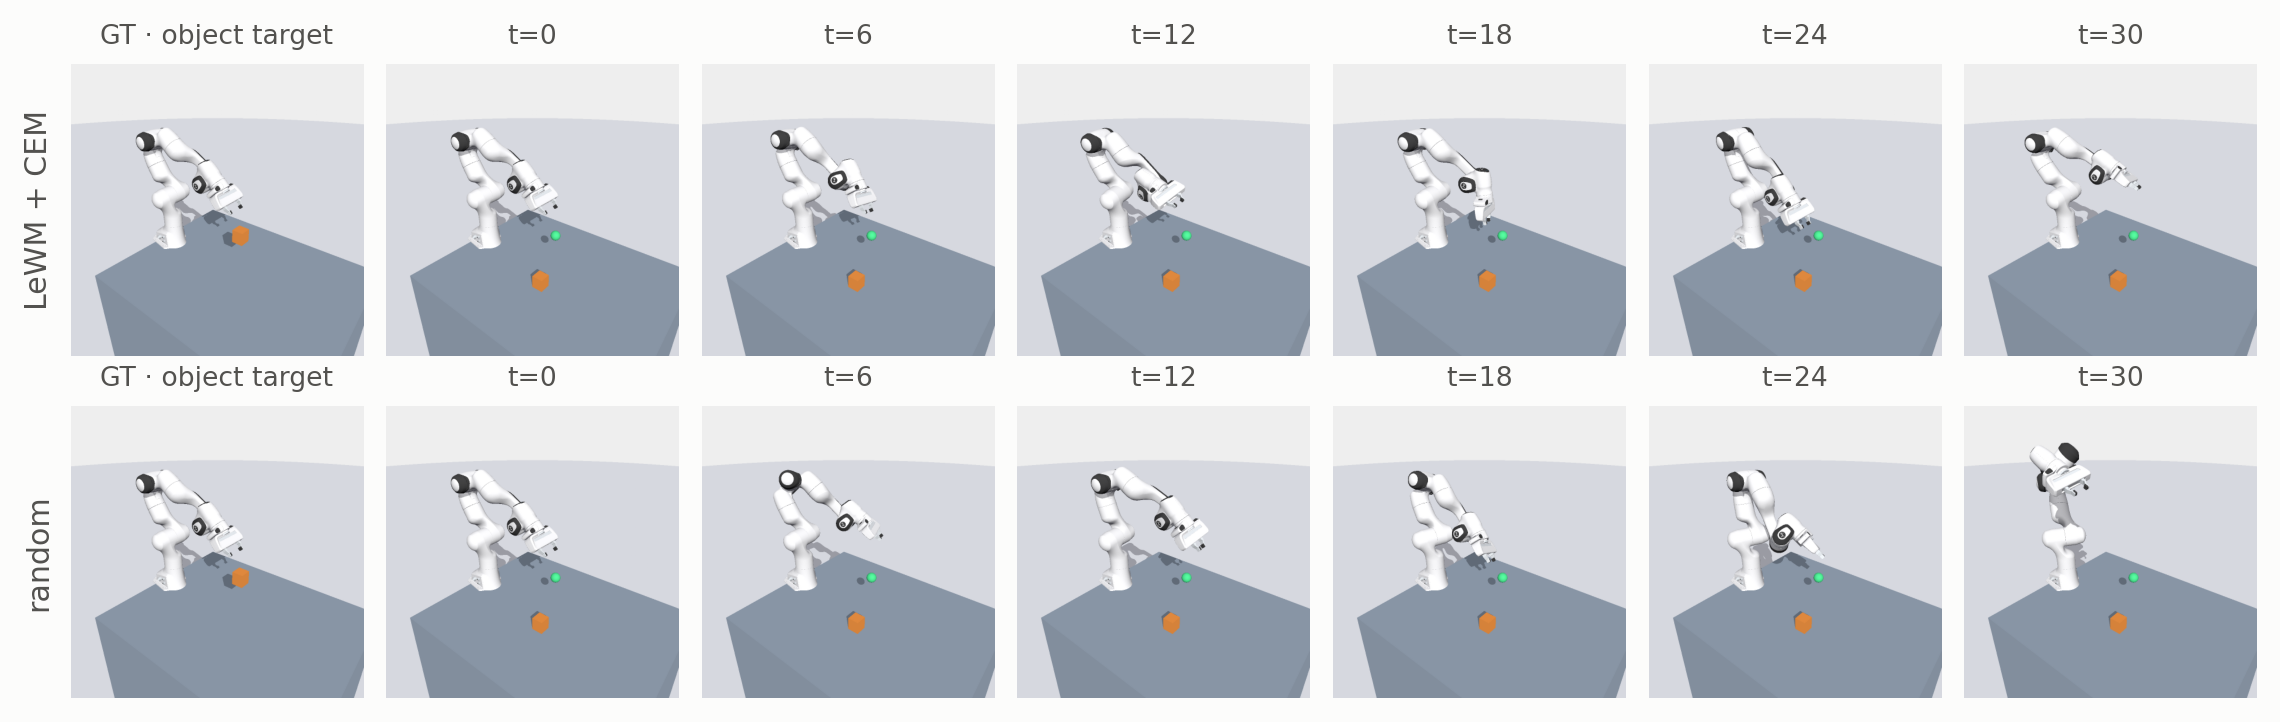

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

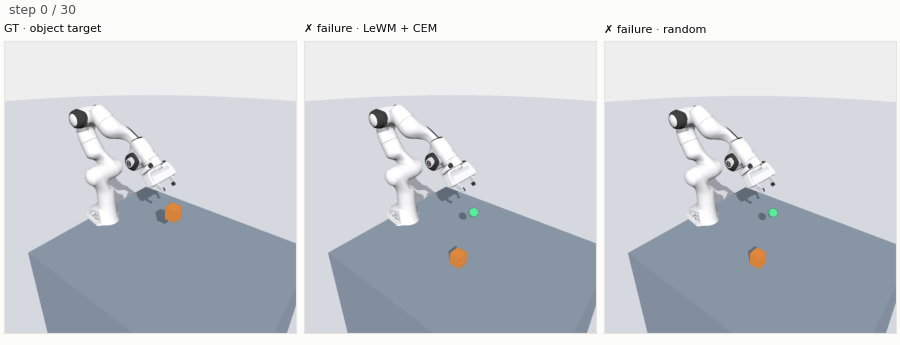

Static preview of the recorded episode. Rerun this cell to view the animation.

In [4]:
compare_quality(FrankaCubeLift, observation="rgb", device="cuda:0")

## Saved comparison

`summary.csv` contains one row per run and policy, including quality, model-input size, presentation size, camera, seed, config hash, and library source hash. Each run has its own manifest, metrics, training curve, GT, episode tensors, and GIFs. Compare task scores within an environment and keep different rendering configurations separate.

In [5]:
rows = write_summary(OUTPUT_DIR, OUTPUT_DIR / "summary.csv")
print(f"Saved {len(rows)} policy rows to {OUTPUT_DIR / 'summary.csv'}")

Saved 18 policy rows to runs/quality_comparison/20261015T115010375079Z/summary.csv
